# Chapter 4 — dataset figures

Figures that show the labels and the features are sound before any model is trained.
Reads only `data/processed/` as written by `prepare_data.py`.

| Figure | Content |
|---|---|
| D1 | Experimental design and bag construction (schematic) |
| D2 | Cells per line × passage, split by well, against the bag size |
| D3 | Lifespan fraction `s` per line with the 10 bins overlaid |
| D4 | PCA / UMAP of manual and latent features, coloured by passage, line and well |
| D5 | Feature correlation heatmap and variance partition (line / passage / well / cell) |
| D6 | Univariate trends of key features with passage, both lines |

D4 and D5 are the key diagnostics: together they show how much of the feature variance is
attributable to passage (the signal) against line and well (the nuisance factors).

In [1]:
from pathlib import Path
import pickle, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from scipy.stats import spearmanr
from scipy.cluster.hierarchy import linkage, leaves_list
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")

REPO    = Path("C:/Users/goofy/PycharmProjects/MILAgeScore")                                # root of the MILAgeScore repo
PROC    = REPO / "data" / "processed"
FIG_DIR = REPO / "thesis_figures" / "chapter4"
TAB_DIR = REPO / "thesis_tables" / "chapter4"
FIG_DIR.mkdir(parents=True, exist_ok=True); TAB_DIR.mkdir(parents=True, exist_ok=True)

P_MIN, P_MAX   = 4, {1: 15, 2: 18}                 # first passage; passage at growth arrest
N_BINS         = 10
CELLS_PER_BAG  = 100                               # <-- set to the value used for the thesis runs
WELL_CAP_FRAC  = 0.5                               # max fraction of a bag drawn from one well
SEED           = 0

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9, "legend.fontsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
C_LINE  = {1: "#1b6ca8", 2: "#d1495b"}
C_BLOCK = {"shape": "#d1495b", "intensity": "#2e8b57", "ratio": "#8e6bbf",
           "texture-distribution": "#e08e0b", "latent": "#1b6ca8"}
BIN_CMAP = plt.get_cmap("viridis", N_BINS)

def savefig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print(f"saved {FIG_DIR / name}.png/.pdf")

def savetab(df, name, **kw):
    df.to_csv(TAB_DIR / f"{name}.csv", **kw); print(f"saved {TAB_DIR / name}.csv")

def block_of(f):
    if f.startswith("latent"): return "latent"
    if f in ("Area", "Perimeter", "Eccentricity", "Circularity", "MinAxisLength", "MaxAxisLength", "AspectRatio", "Extent"): return "shape"
    if f.startswith("ratio"): return "ratio"
    if f.startswith(("mean", "rawIntDen")): return "intensity"
    return "texture-distribution"

## Load

In [2]:
Xm = np.load(PROC / "features_manual.npy"); Xl = np.load(PROC / "features_latent.npy")
manual_cols = list(pickle.load(open(PROC / "manual_cols.pkl", "rb")))
latent_cols = list(pickle.load(open(PROC / "latent_cols.pkl", "rb")))
lab = pd.read_csv(PROC / "labels.csv")
assert len(lab) == len(Xm) == len(Xl), "labels and feature matrices are not row-aligned"

cols  = manual_cols + latent_cols
X     = np.hstack([Xm, Xl]).astype(float)
Z     = (X - X.mean(0)) / X.std(0)                              # z-score over all cells (figures only)
block = pd.Series([block_of(c) for c in cols], index=cols)

lab["cell_line"] = lab["cell_line"].astype(int); lab["passage"] = lab["passage"].astype(int)
lab["s_frac"] = (lab.passage - P_MIN) / (lab.cell_line.map(P_MAX) - P_MIN)
edges = np.linspace(0, 1, N_BINS + 1)
lab["bin"] = np.clip(np.digitize(lab.s_frac, edges[1:-1]), 0, N_BINS - 1)
rc = lab.well_name.str.extract(r"R(\d+)-C(\d+)").astype(float)
lab["row"], lab["col"] = rc[0], rc[1]
lab["well_id"] = lab.groupby(["cell_line", "passage", "well_name"]).ngroup()
if "s" in lab: assert np.allclose(lab.s, lab.s_frac, atol=1e-4), "s in labels.csv differs from (p - p_min)/(p_arrest - p_min)"

print(f"{len(lab):,} cells | {lab.well_id.nunique()} wells | {lab.groupby(['cell_line','passage']).ngroups} line-passage groups | "
      f"{len(manual_cols)} manual + {len(latent_cols)} latent features")
print(lab.groupby("cell_line").size().rename("cells per line").to_string())
print(block.value_counts().to_string())

16,505 cells | 160 wells | 27 line-passage groups | 42 manual + 16 latent features
cell_line
1    7441
2    9064
texture-distribution    19
latent                  16
intensity               10
shape                    8
ratio                    5


## D1 · Experimental design and bag construction

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D1_design_schematic.png/.pdf


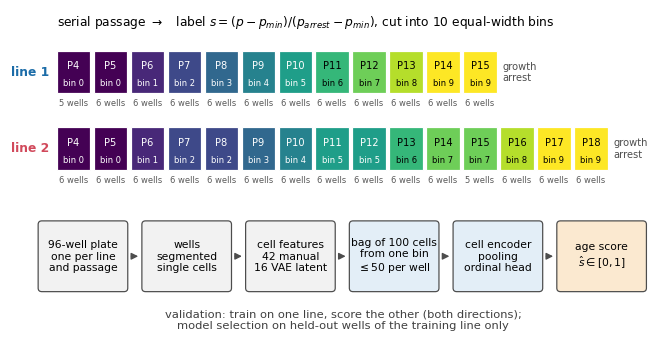

In [3]:
def box(ax, x, y, w, h, text, fc="#f2f2f2", ec="0.3", fs=7.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.06", fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=0.9, color="0.3"))

wells_per_group = lab.groupby(["cell_line", "passage"]).well_id.nunique()
fig = plt.figure(figsize=(7.2, 3.9)); gs = fig.add_gridspec(2, 1, height_ratios=[1.5, 1], hspace=0.02)
ax = fig.add_subplot(gs[0]); ax.set_xlim(3, 19.6); ax.set_ylim(-0.3, 2.9); ax.axis("off")
for i, l in enumerate((1, 2)):
    y = 1.55 - i * 1.25
    ax.text(3.35, y + 0.35, f"line {l}", ha="right", va="center", fontsize=8, color=C_LINE[l], fontweight="bold")
    for p in range(P_MIN, P_MAX[l] + 1):
        b = int(lab[(lab.cell_line == l) & (lab.passage == p)].bin.iloc[0])
        ax.add_patch(plt.Rectangle((p - 0.45, y), 0.9, 0.7, fc=BIN_CMAP(b), ec="w", lw=0.8))
        ax.text(p, y + 0.45, f"P{p}", ha="center", va="center", fontsize=6.5, color="w" if b < 6 else "k")
        ax.text(p, y + 0.17, f"bin {b}", ha="center", va="center", fontsize=5.5, color="w" if b < 6 else "k")
        ax.text(p, y - 0.16, f"{wells_per_group.get((l, p), 0)} wells", ha="center", va="center", fontsize=5.5, color="0.35")
    ax.text(P_MAX[l] + 0.6, y + 0.35, "growth\narrest", ha="left", va="center", fontsize=6.5, color="0.3")
ax.text(3.55, 2.72, r"serial passage $\rightarrow$   label $s = (p - p_{min})/(p_{arrest} - p_{min})$, "
        f"cut into {N_BINS} equal-width bins", fontsize=8, va="center")

ax = fig.add_subplot(gs[1]); ax.set_xlim(0, 10); ax.set_ylim(0, 2.2); ax.axis("off")
cap = int(np.ceil(WELL_CAP_FRAC * CELLS_PER_BAG))
steps = [("96-well plate\none per line\nand passage", "#f2f2f2"), ("wells\nsegmented\nsingle cells", "#f2f2f2"),
         (f"cell features\n{len(manual_cols)} manual\n{len(latent_cols)} VAE latent", "#f2f2f2"),
         (f"bag of {CELLS_PER_BAG} cells\nfrom one bin\n$\\leq${cap} per well", "#e3eef7"),
         ("cell encoder\npooling\nordinal head", "#e3eef7"), ("age score\n$\\hat{s} \\in [0, 1]$", "#fbe9d0")]
w, gap = 1.42, 0.27
for i, (t, fc) in enumerate(steps):
    x = 0.05 + i * (w + gap); box(ax, x, 0.85, w, 1.15, t, fc=fc, fs=7)
    if i: arrow(ax, x - gap + 0.03, 1.425, x - 0.03, 1.425)
ax.text(5, 0.35, "validation: train on one line, score the other (both directions);\n"
        "model selection on held-out wells of the training line only", ha="center", va="center", fontsize=7.5, color="0.25")
savefig(fig, "D1_design_schematic")

## D2 · Cells per line × passage, split by well

Each bar is one (line, passage) group and each segment one well. The dashed line is the bag size;
the dotted line is the largest contribution a single well may make to a bag.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D2_cell_counts.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\dataset_counts.csv
wells with fewer than 100 cells: 62% | cells per well: median 88, range 9–345


cells  wells  min_well  median_well  max_well  \
cell_line passage                                                  
1         4          437      5        59         91.0       108   
          5          566      6        64         93.5       117   
          6         1051      6        92        184.5       229   
          7          441      6        24         82.0       101   
          8         1628      6        92        297.0       345   
          9          578      6        38         86.5       186   
          10         757      6        74        125.0       185   
          11         509      6        40        101.5       111   
          12         451      6        52         77.0        90   
          13         359      6        48         60.0        70   
          14         330      6        28         58.0        80   
          15         334      6        41         53.5        71   
2         4          428      6        39         72.5       102   
          5          524      6        27        100.5       149   
          6          760      6        77        105.0       221   
          7          742      6        12        145.5       170   
          8         1682      6       199        276.5       336   
          9          664      6        23        118.5       168   
          10         327      6        48         55.0        61   
          11         397      6         9         72.0       123   
          12        1067      6       144        172.5       237   
          13         490      6        65         80.0       107   
          14         416      6        49         64.5        91   
          15         236      5        27         52.0        71   
          16         444      6        39         59.0       124   
          17         539      6        61         94.5       100   
          18         348      6        39         53.5        84   

                   wells_below_bag_size  usable_cells_under_cap  
cell_line passage                                                
1         4                           3                     250  
          5                           4                     300  
          6                           1                     300  
          7                           5                     274  
          8                           1                     300  
          9                           3                     288  
          10                          2                     300  
          11                          3                     288  
          12                          6                     300  
          13                          6                     298  
          14                          6                     257  
          15                          6                     288  
2         4                           5                     287  
          5                           3                     262  
          6                           3                     300  
          7                           1                     262  
          8                           0                     300  
          9                           1                     273  
          10                          6                     298  
          11                          4                     224  
          12                          0                     300  
          13                          5                     300  
          14                          6                     299  
          15                          5                     205  
          16                          4                     289  
          17                          4                     300  
          18                          6                     280

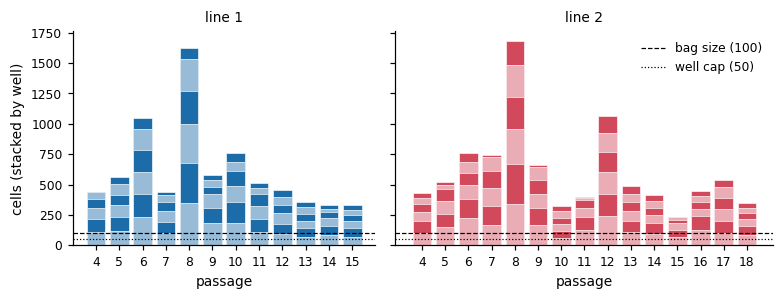

In [4]:
counts = lab.groupby(["cell_line", "passage", "well_id"]).size().rename("n").reset_index()
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.8), sharey=True, gridspec_kw={"width_ratios": [12, 15]})
for ax, l in zip(axes, (1, 2)):
    d = counts[counts.cell_line == l]
    for p, g in d.groupby("passage"):
        bottom = 0
        for k, n in enumerate(sorted(g.n, reverse=True)):
            ax.bar(p, n, bottom=bottom, color=C_LINE[l], alpha=0.45 + 0.55 * (k % 2), ec="w", lw=0.4, width=0.8); bottom += n
    ax.axhline(CELLS_PER_BAG, color="k", ls="--", lw=0.8, label=f"bag size ({CELLS_PER_BAG})")
    ax.axhline(cap, color="k", ls=":", lw=0.8, label=f"well cap ({cap})")
    ax.set_xticks(sorted(d.passage.unique())); ax.set_xlabel("passage"); ax.set_title(f"line {l}")
axes[0].set_ylabel("cells (stacked by well)")
axes[1].legend(loc="upper right")
fig.tight_layout(); savefig(fig, "D2_cell_counts")

grp = counts.groupby(["cell_line", "passage"]).n.agg(cells="sum", wells="size", min_well="min", median_well="median", max_well="max")
grp["wells_below_bag_size"] = counts.assign(b=counts.n < CELLS_PER_BAG).groupby(["cell_line", "passage"]).b.sum()
grp["usable_cells_under_cap"] = counts.assign(c=counts.n.clip(upper=cap)).groupby(["cell_line", "passage"]).c.sum()
savetab(grp, "dataset_counts")
print(f"wells with fewer than {CELLS_PER_BAG} cells: {(counts.n < CELLS_PER_BAG).mean():.0%} | "
      f"cells per well: median {counts.n.median():.0f}, range {counts.n.min()}–{counts.n.max()}")
grp

## D3 · Label grid

Lifespan fraction per passage for each line, with the bin boundaries overlaid. Because line 2
arrests three passages later, the same passage number falls in a different bin in the two lines
(right panel). This offset is what later allows the two candidate scales, lifespan fraction and
passage number, to be told apart.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D3_label_grid.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\label_grid.csv


s        bin        cells         wells     
cell_line     1     2    1    2       1       2     1    2
passage                                                   
4          0.00  0.00  0.0  0.0   437.0   428.0   5.0  6.0
5          0.09  0.07  0.0  0.0   566.0   524.0   6.0  6.0
6          0.18  0.14  1.0  1.0  1051.0   760.0   6.0  6.0
7          0.27  0.21  2.0  2.0   441.0   742.0   6.0  6.0
8          0.36  0.29  3.0  2.0  1628.0  1682.0   6.0  6.0
9          0.45  0.36  4.0  3.0   578.0   664.0   6.0  6.0
10         0.55  0.43  5.0  4.0   757.0   327.0   6.0  6.0
11         0.64  0.50  6.0  5.0   509.0   397.0   6.0  6.0
12         0.73  0.57  7.0  5.0   451.0  1067.0   6.0  6.0
13         0.82  0.64  8.0  6.0   359.0   490.0   6.0  6.0
14         0.91  0.71  9.0  7.0   330.0   416.0   6.0  6.0
15         1.00  0.79  9.0  7.0   334.0   236.0   6.0  5.0
16          NaN  0.86  NaN  8.0     NaN   444.0   NaN  6.0
17          NaN  0.93  NaN  9.0     NaN   539.0   NaN  6.0
18          NaN  1.00  NaN  9.0     NaN   348.0   NaN  6.0

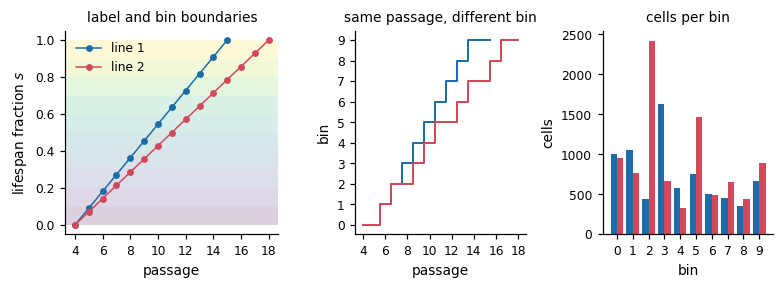

In [5]:
g = lab.groupby(["cell_line", "passage"]).agg(s=("s_frac", "first"), bin=("bin", "first"), cells=("bin", "size"),
                                              wells=("well_id", "nunique")).reset_index()
g["label"] = g.bin / (N_BINS - 1)
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.7), gridspec_kw={"width_ratios": [1.25, 1, 1]})
ax = axes[0]
for b in range(N_BINS): ax.axhspan(edges[b], edges[b + 1], color=BIN_CMAP(b), alpha=0.18, lw=0)
for l in (1, 2):
    d = g[g.cell_line == l]; ax.plot(d.passage, d.s, "o-", ms=3.5, lw=1, color=C_LINE[l], label=f"line {l}")
ax.set_xlabel("passage"); ax.set_ylabel("lifespan fraction $s$"); ax.set_xticks(range(4, 19, 2)); ax.legend(loc="upper left")
ax.set_title("label and bin boundaries")
ax = axes[1]
m = g.pivot(index="passage", columns="cell_line", values="bin")
for l in (1, 2): ax.step(m.index, m[l], where="mid", color=C_LINE[l], lw=1.3, label=f"line {l}")
ax.set_xlabel("passage"); ax.set_ylabel("bin"); ax.set_yticks(range(N_BINS)); ax.set_xticks(range(4, 19, 2))
ax.set_title("same passage, different bin")
ax = axes[2]
cb = g.groupby(["cell_line", "bin"]).cells.sum().unstack(0)
for i, l in enumerate((1, 2)): ax.bar(cb.index + (i - 0.5) * 0.4, cb[l], width=0.4, color=C_LINE[l], label=f"line {l}")
ax.set_xlabel("bin"); ax.set_ylabel("cells"); ax.set_xticks(range(N_BINS)); ax.set_title("cells per bin")
fig.tight_layout(); savefig(fig, "D3_label_grid")
savetab(g, "label_grid", index=False)
g.pivot(index="passage", columns="cell_line", values=["s", "bin", "cells", "wells"]).round(2)

## D4 · Low-dimensional structure

PCA of each feature block (z-scored), coloured by passage, by line, and by well within a single
passage. A sound dataset shows a gradient with passage, overlapping lines, and no well clusters.
The table below the figure puts numbers on what the eye sees: the share of variance in the first
ten principal components explained by each factor.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D4_pca.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D4_umap.png/.pdf


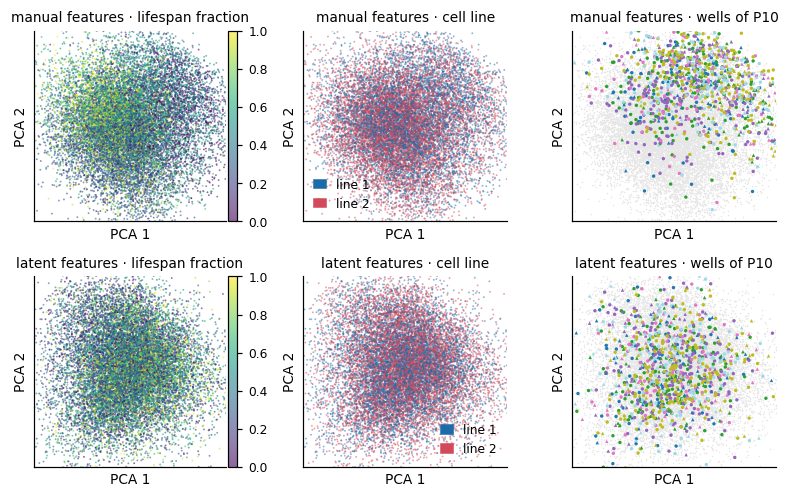

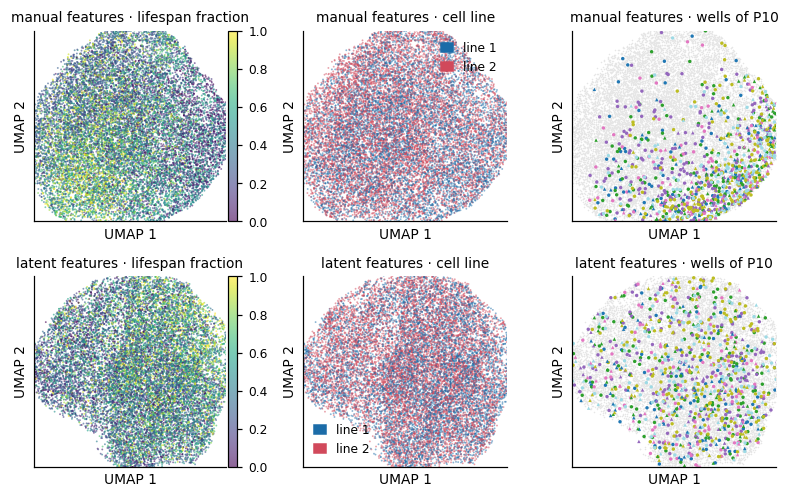

In [6]:
def eta2(y, groups):
    """Share of the variance of y explained by a grouping factor (one-way eta squared), column-wise."""
    y = np.asarray(y, float); gm = y.mean(0); ss_t = ((y - gm) ** 2).sum(0); ss_b = np.zeros(y.shape[1])
    for _, idx in pd.Series(np.arange(len(y))).groupby(np.asarray(groups)):
        yi = y[idx.to_numpy()]; ss_b += len(yi) * (yi.mean(0) - gm) ** 2
    return ss_b / ss_t

def embed(Zb, method="pca"):
    if method == "umap":
        import umap
        return umap.UMAP(n_neighbors=30, min_dist=0.3, random_state=SEED).fit_transform(PCA(10, random_state=SEED).fit_transform(Zb))
    return PCA(2, random_state=SEED).fit_transform(Zb)

def structure_figure(method="pca", ref_passage=10):
    rng = np.random.default_rng(SEED); order = rng.permutation(len(lab))          # random draw order: no line hides the other
    fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.6))
    for i, (name, idx) in enumerate((("manual", slice(0, len(manual_cols))), ("latent", slice(len(manual_cols), None)))):
        E = embed(np.clip(Z[:, idx], -5, 5), method); lo, hi = np.percentile(E, [0.5, 99.5], axis=0)
        ax = axes[i, 0]
        sca = ax.scatter(E[order, 0], E[order, 1], c=lab.s_frac.to_numpy()[order], s=1.5, cmap="viridis", lw=0, alpha=0.6, rasterized=True)
        ax.set_title(f"{name} features · lifespan fraction"); plt.colorbar(sca, ax=ax, pad=0.01, fraction=0.05)
        ax = axes[i, 1]
        ax.scatter(E[order, 0], E[order, 1], c=lab.cell_line.map(C_LINE).to_numpy()[order], s=1.5, lw=0, alpha=0.5, rasterized=True)
        ax.set_title(f"{name} features · cell line")
        ax.legend(handles=[Patch(color=C_LINE[l], label=f"line {l}") for l in (1, 2)], loc="best", handlelength=1)
        ax = axes[i, 2]
        sel = (lab.passage == ref_passage).to_numpy(); wl = lab.well_id[sel].astype("category").cat.codes
        mk = lab.cell_line[sel].map({1: "o", 2: "^"}).to_numpy()
        ax.scatter(E[~sel, 0], E[~sel, 1], c="0.9", s=1, lw=0, rasterized=True)
        for m_ in ("o", "^"):
            k = mk == m_; ax.scatter(E[sel][k, 0], E[sel][k, 1], c=wl[k], cmap="tab20", s=5, marker=m_, lw=0, rasterized=True)
        ax.set_title(f"{name} features · wells of P{ref_passage}")
        for ax in axes[i]:
            ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_xticks([]); ax.set_yticks([])
            ax.set_xlabel(f"{method.upper()} 1"); ax.set_ylabel(f"{method.upper()} 2")
    fig.tight_layout(); return fig

savefig(structure_figure("pca"), "D4_pca")
try:
    savefig(structure_figure("umap"), "D4_umap")
except ImportError:
    print("umap-learn not installed: UMAP version skipped (pip install umap-learn)")

In [7]:
rows = []
for name, idx in (("manual", slice(0, len(manual_cols))), ("latent", slice(len(manual_cols), None))):
    pca = PCA(10, random_state=SEED).fit(np.clip(Z[:, idx], -5, 5)); S = pca.transform(np.clip(Z[:, idx], -5, 5))
    wgt = pca.explained_variance_ratio_ / pca.explained_variance_ratio_.sum()
    lp = lab.cell_line.astype(str) + "_" + lab.passage.astype(str)
    rows.append({"block": name, "variance in 10 PCs": pca.explained_variance_ratio_.sum(),
                 "line": (eta2(S, lab.cell_line) * wgt).sum(), "line + passage": (eta2(S, lp) * wgt).sum(),
                 "line + passage + well": (eta2(S, lab.well_id) * wgt).sum(),
                 "PC1 vs s (Spearman)": spearmanr(S[:, 0], lab.s_frac)[0]})
pc_tab = pd.DataFrame(rows).set_index("block")
pc_tab["passage | line"] = pc_tab["line + passage"] - pc_tab["line"]
pc_tab["well | passage"] = pc_tab["line + passage + well"] - pc_tab["line + passage"]
savetab(pc_tab, "pc_variance_by_factor"); pc_tab.round(3)

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\pc_variance_by_factor.csv


,variance in 10 PCs,line,line + passage,line + passage + well,PC1 vs s (Spearman),passage | line,well | passage
block,,,,,,,
manual,0.935,0.005,0.140,0.173,-0.225,0.135,0.033
latent,0.856,0.001,0.014,0.024,0.094,0.013,0.010


## D5 · Feature correlation and variance partition

Left: Spearman correlation between features (hierarchically ordered). Blocks of redundant features
appear as squares. Right: nested decomposition of each feature's variance into line, passage within
line, well within passage, and cell within well. A feature is useful for age scoring when the passage
share is large relative to the well share; a large line share marks a donor-specific feature.

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\variance_partition.csv
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D5_correlation_and_variance_partition.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\variance_partition_by_block.csv
feature pairs with |rho| > 0.9: 22


,line,passage,well,cell
block,,,,
intensity,0.002,0.121,0.040,0.837
latent,0.000,0.006,0.010,0.984
ratio,0.007,0.155,0.053,0.789
shape,0.004,0.076,0.015,0.904
texture-distribution,0.005,0.156,0.032,0.814
all,0.003,0.090,0.028,0.868


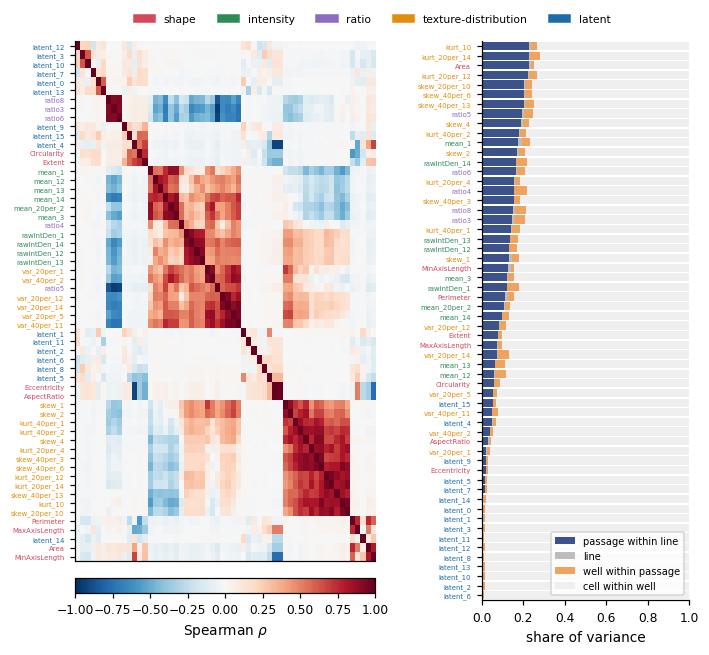

In [8]:
rng = np.random.default_rng(SEED); sub = rng.choice(len(Z), min(len(Z), 8000), replace=False)
C = pd.DataFrame(Z[sub], columns=cols).corr(method="spearman")
order = leaves_list(linkage(C.to_numpy(), "average", metric="correlation")); Co = C.iloc[order, order]

lp = (lab.cell_line.astype(str) + "_" + lab.passage.astype(str)).to_numpy()
e_line, e_lp, e_well = eta2(Z, lab.cell_line), eta2(Z, lp), eta2(Z, lab.well_id)
vp = pd.DataFrame({"line": e_line, "passage": e_lp - e_line, "well": e_well - e_lp, "cell": 1 - e_well}, index=cols)
vp["block"] = block; vp["passage_to_well"] = vp.passage / vp.well
vp = vp.sort_values("passage", ascending=False); savetab(vp, "variance_partition")

fig = plt.figure(figsize=(7.2, 6.6)); gs = fig.add_gridspec(1, 2, width_ratios=[1.45, 1], wspace=0.42)
ax = fig.add_subplot(gs[0])
im = ax.imshow(Co, cmap="RdBu_r", vmin=-1, vmax=1, interpolation="nearest", aspect="auto")
ax.set_xticks([]); ax.set_yticks(range(len(Co))); ax.set_yticklabels(Co.index, fontsize=4.5)
for t, f in zip(ax.get_yticklabels(), Co.index): t.set_color(C_BLOCK[block[f]])
plt.colorbar(im, ax=ax, orientation="horizontal", pad=0.03, fraction=0.04, label=r"Spearman $\rho$")
ax = fig.add_subplot(gs[1]); left = np.zeros(len(vp)); y = np.arange(len(vp))
for k, c in (("passage", "#3b528b"), ("line", "#bdbdbd"), ("well", "#f0a35e"), ("cell", "#efefef")):
    ax.barh(y, vp[k], left=left, color=c, label={"passage": "passage within line", "well": "well within passage", "cell": "cell within well"}.get(k, k), height=0.85); left += vp[k].to_numpy()
ax.set_yticks(y); ax.set_yticklabels(vp.index, fontsize=4.5); ax.set_ylim(len(vp) - 0.5, -0.5); ax.set_xlim(0, 1)
for t, f in zip(ax.get_yticklabels(), vp.index): t.set_color(C_BLOCK[block[f]])
ax.set_xlabel("share of variance"); ax.legend(loc="lower right", fontsize=6.5, frameon=True)
fig.legend(handles=[Patch(color=v, label=k) for k, v in C_BLOCK.items()], ncol=5, loc="upper center", fontsize=7, bbox_to_anchor=(0.5, 0.93))
savefig(fig, "D5_correlation_and_variance_partition")

vb = vp.groupby("block")[["line", "passage", "well", "cell"]].median()
vb.loc["all"] = vp[["line", "passage", "well", "cell"]].median(); savetab(vb, "variance_partition_by_block")
print(f"feature pairs with |rho| > 0.9: {(np.abs(C.to_numpy())[np.triu_indices(len(C), 1)] > 0.9).sum()}")
vb.round(3)

## D6 · Univariate trends with passage

Spearman correlation between passage and the per-passage median of every feature, for each line
separately. Features in the upper-right and lower-left corners change in the same direction in both
lines. The twelve strongest shared trends are plotted below (median and inter-quartile range of well
medians).

saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_tables\chapter4\univariate_trends.csv
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D6a_trend_agreement.png/.pdf
saved C:\Users\goofy\PycharmProjects\MILAgeScore\thesis_figures\chapter4\D6b_univariate_trends.png/.pdf
features with |rho| > 0.7 in both lines and the same sign: 15 of 58


,n,same_sign,median_abs_rho_L1,median_abs_rho_L2
block,,,,
intensity,10,10,0.45,0.44
latent,16,13,0.38,0.39
ratio,5,5,0.91,0.87
shape,8,8,0.87,0.83
texture-distribution,19,19,0.46,0.34


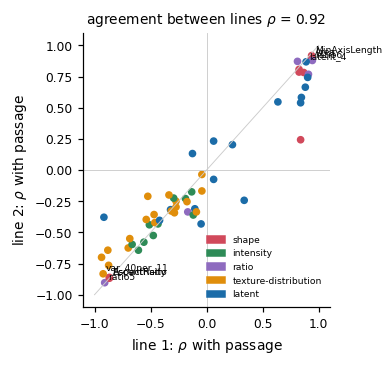

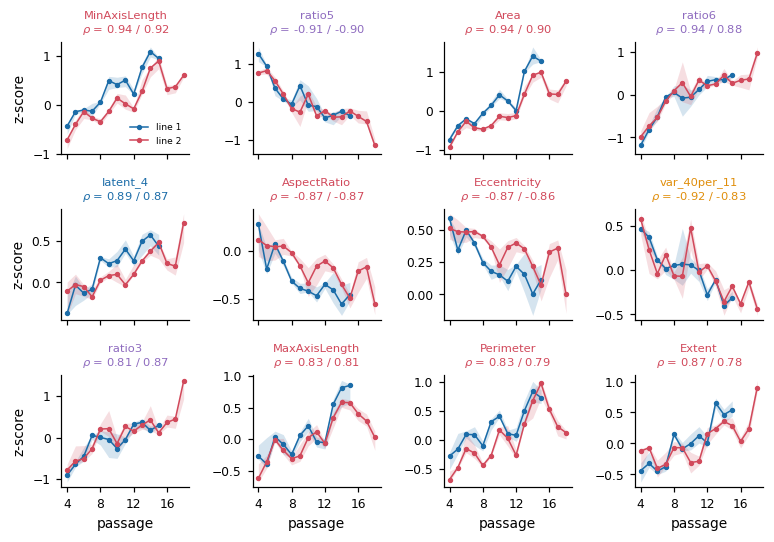

In [10]:
wm = pd.DataFrame(Z, columns=cols).assign(cell_line=lab.cell_line, passage=lab.passage, well_id=lab.well_id) \
       .groupby(["cell_line", "passage", "well_id"]).median().reset_index()
gmed = wm.groupby(["cell_line", "passage"])[cols].median()
rho = pd.DataFrame({l: [spearmanr(gmed.loc[l].index, gmed.loc[l][c])[0] for c in cols] for l in (1, 2)}, index=cols)
rho["block"] = block; rho["shared"] = np.sign(rho[1]) == np.sign(rho[2])
rho["strength"] = rho[[1, 2]].abs().min(axis=1) * rho.shared
rho = rho.sort_values("strength", ascending=False); savetab(rho, "univariate_trends")

fig, ax = plt.subplots(figsize=(3.6, 3.4))
ax.scatter(rho[1], rho[2], c=rho.block.map(C_BLOCK), s=16)
for f in rho.index[:8]: ax.annotate(f, (rho.loc[f, 1], rho.loc[f, 2]), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax.axhline(0, color="0.8", lw=0.6); ax.axvline(0, color="0.8", lw=0.6); ax.plot([-1, 1], [-1, 1], color="0.8", lw=0.6)
ax.set_xlabel(r"line 1: $\rho$ with passage"); ax.set_ylabel(r"line 2: $\rho$ with passage")
ax.legend(handles=[Patch(color=v, label=k) for k, v in C_BLOCK.items()], fontsize=6, loc="lower right")
ax.set_title(rf"agreement between lines $\rho$ = {spearmanr(rho[1], rho[2])[0]:.2f}")
fig.tight_layout(); savefig(fig, "D6a_trend_agreement")

top = rho.index[:12]
fig, axes = plt.subplots(3, 4, figsize=(7.2, 5.0), sharex=True)
for ax, f in zip(axes.ravel(), top):
    for l in (1, 2):
        d = wm[wm.cell_line == l].groupby("passage")[f].quantile([0.25, 0.5, 0.75]).unstack()
        ax.fill_between(d.index, d[0.25], d[0.75], color=C_LINE[l], alpha=0.18, lw=0)
        ax.plot(d.index, d[0.5], "o-", ms=2.5, lw=1, color=C_LINE[l], label=f"line {l}")
    ax.set_title(f"{f}\n" + rf"$\rho$ = {rho.loc[f, 1]:.2f} / {rho.loc[f, 2]:.2f}", fontsize=7.5, color=C_BLOCK[block[f]])
    ax.set_xticks(range(4, 19, 4))
for ax in axes[-1]: ax.set_xlabel("passage")
for ax in axes[:, 0]: ax.set_ylabel("z-score")
axes[0, 0].legend(fontsize=6)
fig.tight_layout(); savefig(fig, "D6b_univariate_trends")
print(f"features with |rho| > 0.7 in both lines and the same sign: {(rho.strength > 0.7).sum()} of {len(rho)}")
rho.groupby("block").agg(n=("strength", "size"), same_sign=("shared", "sum"), median_abs_rho_L1=(1, lambda x: x.abs().median()),
                         median_abs_rho_L2=(2, lambda x: x.abs().median())).round(2)